# Exercise 2: Heredero Louis & Amacker Olivier

# Random Forests


In this notebook we are using random forests and other similar ensemble methodes in order to predict the state (awake, REM-sleeo, nonREM-sleep) of a mouse based on its electrical brain activity.

In [1]:
#IMPORTS PACKAGES
import os
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from scipy.stats import randint

In [2]:
path = os.path.join(os.getcwd(), 'EEG_mouse_data.csv')
data_mice = pd.read_csv(path)

In [3]:
#CREATE X AND Y FROM DATAFRAME / SPLIT THE DATA INTO TRAIN/TEST
X = data_mice.drop(['EEGv','state'],axis=1).to_numpy()
Y = data_mice['state'].values

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## HYPERPARAMETERS OPTIMIZATION

Many different hyperparameters can be tuned in order to obtain a good random forest classifier. In this example, we will look specifically at the number of trees in the random forest (n_estimators), The number of features to consider at each split (max_features), the maximum depth of the tree (max_depth) and the minimum number of samples required to be at a leaf node (min_samples_leaf). 

### Randomized Search

As a first optimization step, we will perform a RandomizedSearchCV on the training set. This process randomly samples different combinations of hyperparameters within specified ranges and evaluates their performance using cross-validation. It gives us a general idea of which hyperparameter ranges are promising. This process can take a lot of time if we want to explore enough sets of hyperparameters. Therefore, it is strongly advised that you **do not re-run the code for the part on randomized search**. Looking at the figures should be enough to answer the questions.

In [10]:
##### This cell is not meant to be executed####

#RANDOMLY CHOSE SET OF HYPERPARAMETERS TO DETERMINE RANGE OF INTEREST
n_iter=1000
# Define parameter distributions
param_dist = {
    'n_estimators': list(range(1, 211, 10)),
    'max_features': randint(5,20),
    'max_depth': list(range(1, 50, 2)),  
    'min_samples_leaf': randint(1, 25)  
}
# Create a random forest classifier
clf = RandomForestClassifier(random_state=0, class_weight='balanced')

# Create randomized search object
random_search = RandomizedSearchCV(estimator=clf, param_distributions=param_dist, n_iter=n_iter, cv=4, scoring='balanced_accuracy', verbose=0, n_jobs = -1, random_state=0)

# Fit randomized search to training data
random_search = random_search.fit(X_train, Y_train)


# Get best estimator
best_clf = random_search.best_estimator_

# Get results
results = random_search.cv_results_

In [11]:
# Print best parameters
print('Best parameters:', random_search.best_params_)

Best parameters: {'max_depth': 45, 'max_features': 17, 'min_samples_leaf': 11, 'n_estimators': 91}


#### Plot Validation Scores
The following plots show how the validation scores (balanced_accuracy) change according to each individual hyperparameter.


Q2.1: For each of the hyperparameter: Is there a range of value giving particularly good results? Or particularly bad results?

**A2.1**: Yes, we find the best results with the following hyper-parameters
  - `max_depth`: >=15
  - `n_estimators`: >=10
  - `max_features`: >=10
  - `min_samples`: >=7, <=15

Q2.2: These representations give valuable information about hyperparameters. It is nevertheless insufficient. What are/is the main problem(s) with those graphs in your opinion?

**A2.2**: They only show the individual effect of each parameter and hide potential interactions between multiple parameters. Additionally, scatter plots are not always great to see the distribution of points.

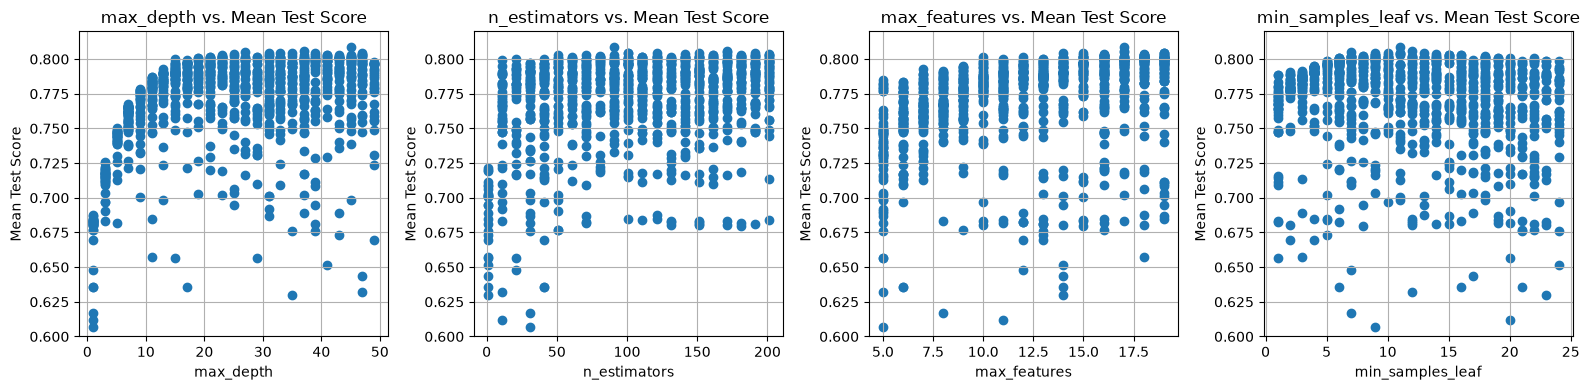

In [12]:
##### This cell is not meant to be executed####
hyperparameters_to_plot = ['param_max_depth', 'param_n_estimators', 'param_max_features', 'param_min_samples_leaf']
hyperparameter_labels = ['max_depth', 'n_estimators', 'max_features', 'min_samples_leaf']


fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4))

for i, hyperparam in enumerate(hyperparameters_to_plot):
    axes[i].scatter(results[hyperparam], results['mean_test_score'], marker='o')
    axes[i].set_xlabel(hyperparameter_labels[i])
    axes[i].set_ylabel('Mean Test Score')
    axes[i].set_title(f'{hyperparameter_labels[i]} vs. Mean Test Score')
    axes[i].grid(True)
    axes[i].set_ylim(0.6, 0.82)

plt.tight_layout()
plt.show()

#### Heatmaps
Q2.3: What do the following plots represent? 

**A2.3**: They represent the score distribution for each pair of parameters in their respective ranges. For example, the first one represents the measured score when varying both `max_depth` and `max_features`.

Q2.4: What do the white spots (=empty spots) in the heatmaps mean?

**A2.4**: White spots are combination of parameter values which have not been tested and thus for which we haven't computed a score.

Q2.5: How do those plots address the limitation of the previous visualizations? 

**A2.5**: Heatmaps like these help visualize interactions between parameters and spot positive / negative influence on each other.

/home/benoit.hohl/miniconda3/envs/o2score/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/benoit.hohl/miniconda3/envs/o2score/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


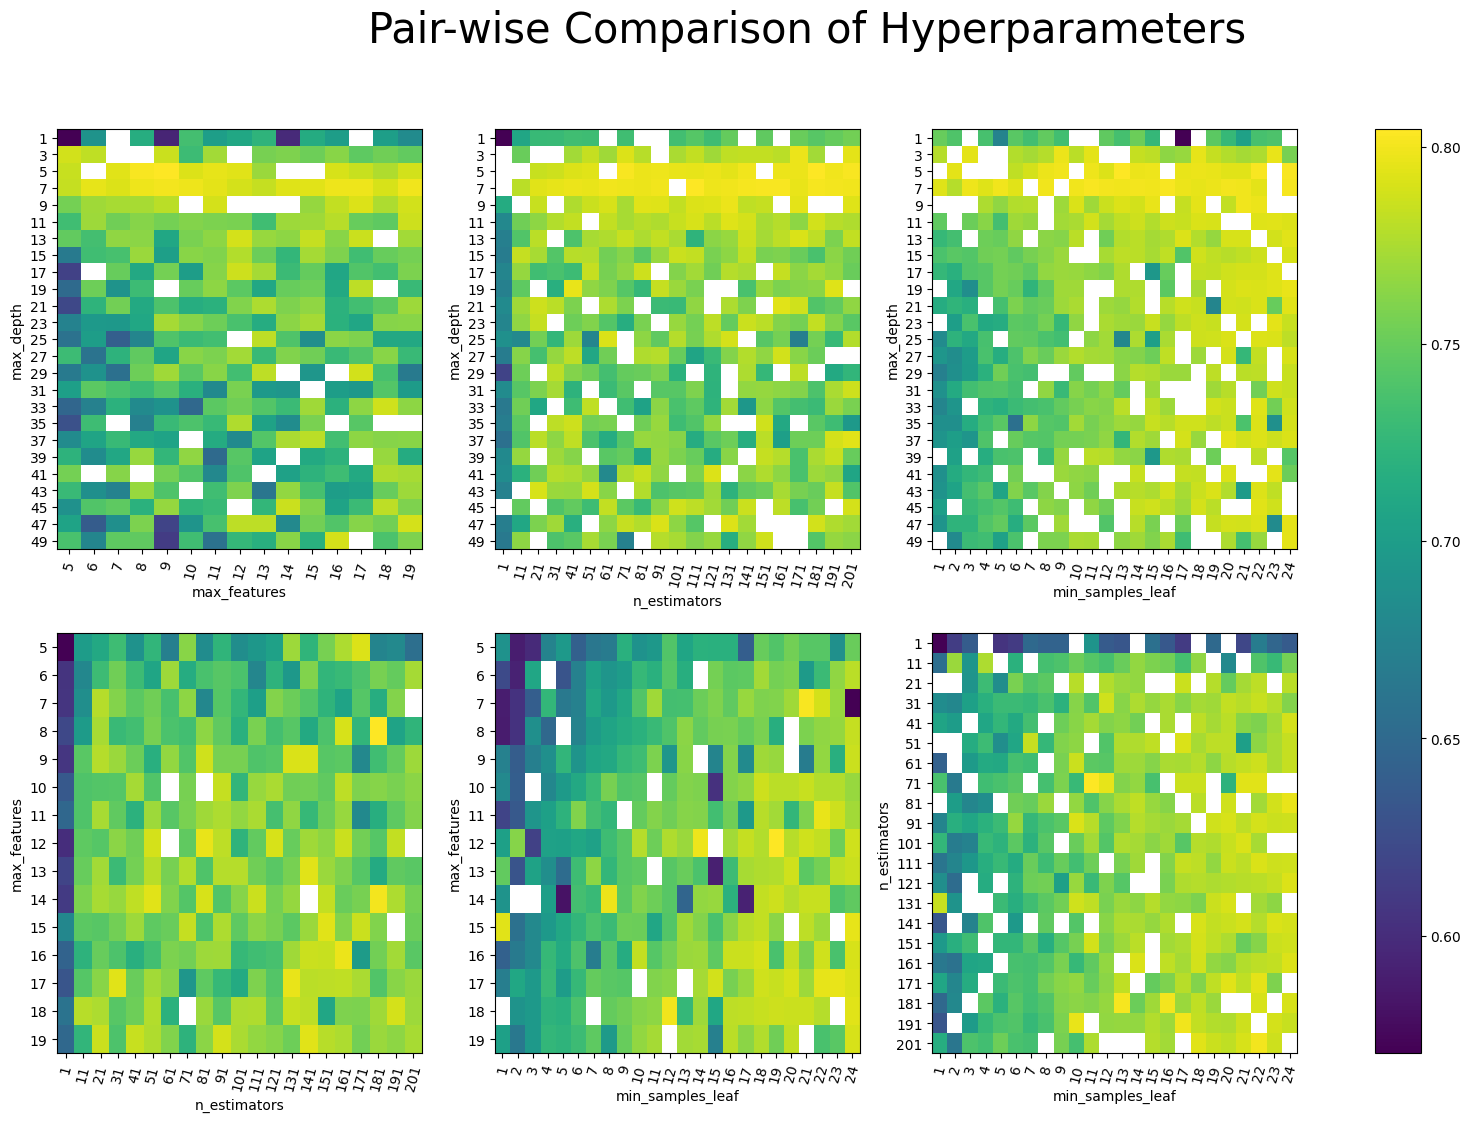

In [11]:
##### This cell is not meant to be executed####
# Convert masked arrays to regular arrays
max_depth_values = results['param_max_depth'].data
n_estimators_values = results['param_n_estimators'].data
max_features_values = results['param_max_features']
min_samples_leaf_values = results['param_min_samples_leaf']

hyperparameters = [max_depth_values,  max_features_values,n_estimators_values, min_samples_leaf_values]
hyperparameter_labels = ['max_depth', 'max_features','n_estimators', 'min_samples_leaf']

num_hyperparameters = len(hyperparameters)

# Calculate the number of rows required based on the number of hyperparameters and three columns
num_rows = (num_hyperparameters + 2) // 3  # Use integer division

fig, axes = plt.subplots(num_rows, 3, figsize=(20, 12))
fig.suptitle('Pair-wise Comparison of Hyperparameters',fontsize=30)

subplot_index = 0  # Initialize the subplot index

for i in range(num_hyperparameters):
    for j in range(i + 1, num_hyperparameters):  # Iterate over unique pairs only
        x_values = hyperparameters[i]
        y_values = hyperparameters[j]

        row_index = subplot_index // 3  # Calculate the row index based on the current subplot's position
        col_index = subplot_index % 3  # Calculate the column index based on the current subplot's position

        heatmap_data = np.zeros((len(np.unique(x_values)), len(np.unique(y_values))))

        for m, x_val in enumerate(np.unique(x_values)):
            for n, y_val in enumerate(np.unique(y_values)):
                mask = (x_values == x_val) & (y_values == y_val) #identifies data points where the hyperparameters match current evaluated combination 
                mean_score = np.mean(results['mean_test_score'][mask]) # average test score for a particular combination of x_val and y_val.
                heatmap_data[m, n] = mean_score

        im = axes[row_index, col_index].imshow(heatmap_data, cmap='viridis', aspect='auto', interpolation=None)

        axes[row_index, col_index].set_xticks(np.arange(len(np.unique(y_values))))
        axes[row_index, col_index].set_yticks(np.arange(len(np.unique(x_values))))
        axes[row_index, col_index].set_xticklabels(np.unique(y_values), rotation=75)
        axes[row_index, col_index].set_yticklabels(np.unique(x_values))

        axes[row_index, col_index].set_xlabel(hyperparameter_labels[j])
        axes[row_index, col_index].set_ylabel(hyperparameter_labels[i])

        subplot_index += 1  # Increment the subplot index

plt.colorbar(im, ax=axes.ravel().tolist())
plt.show()

### Grid Search

Q2.6: What is grid search? Explain by giving real examples from this specific task.

**A2.6**: Grid search is a more systematic approach. Instead of taking random values in predefined ranges for each parameter, it explores an N-dimensional grid of predefined values (where N is the number of parameters). This approach, while more exhaustive, can also be more computationally expensive as the explored space can become very big.

Q2.7: Use the plots above to narrow the range of hyperparameters you want to explore. Which values did you choose to test for each parameter? Justify your choices.

**A2.7**: Given the above plots, we chose the following ranges:
  - `max_depth` $\in [3;9]$: we can see in all 3 plots related to this parameter that these values yield particularly good results (yellow)
  - `max_features` $\in [12;20]$: we can see that values below 10-12 yield slightly worse results. We also want to minimize the parameter space by reducing ranges if possible
  - `n_estimators` $\in [70;200]$: very low values (<10) seem to yield bad results. Above 10, no particular trend can be observed. We might want to reduce this range if the parameter space is too big and expensive to explore
  - `min_samples_leaf` $\in [15;25]$: looking at the heatmaps, it seems the higher the value, the better the results. 15 seems like a good threshold above which scores get quite good

Exercise 2.1: Once you know which values of hyperparameters you want to explore, complete the following code to perform a grid search on those values. Remember that the more values you choose to test, the longer the computational time required.

In [5]:
#HYPERPARAMETERS FINETUNING WITH GRID SEARCH

#Define parameter grid
param_grid = {
    'n_estimators': [80, 100, 120, 140],   # 4 values
    'max_features': [12, 14, 16, 18, 20],  # 5 values
    'max_depth': [3, 5, 7, 9],             # 4 values
    'min_samples_leaf': [17, 19, 21, 23]   # 4 values
}  # 4 * 5 * 4 * 4 = 320 data points

# 4 folds -> 320 * 4 = 1'280

#GRID SEARCH TO FIND BEST PARAMETERS
# Create random forest classifier
clf = RandomForestClassifier(random_state=0,class_weight='balanced')

# Create grid search object
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=4, n_jobs = -1, scoring='balanced_accuracy',verbose=2)

# Fit grid search to training data
grid_search = grid_search.fit(X_train,Y_train)

# Print best parameters
print('Best parameters:', grid_search.best_params_)

Fitting 4 folds for each of 320 candidates, totalling 1280 fits


[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=80; total time=   2.8s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=80; total time=   2.8s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=80; total time=   3.1s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=100; total time=   3.1s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=100; total time=   3.5s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=100; total time=   3.8s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=100; total time=   3.9s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=80; total time=   3.9s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=120; total time=   3.8s
[CV] END max_depth=3, max_features=12, min_samples_leaf=17, n_estimators=120; total time=   4.2s
[CV] END max_depth=3, max_features

**Result**:
- `max_depth` = 9
- `max_features` = 18
- `min_samples_leaf` = 17
- `n_estimators` = 100

### FINAL MODEL TRAINING

It is now time to train your final RF model. Choose one final value for each of the hyperparameters based on your grid search.

Q2.8: Which value did you choose for each hyperparameter? Why?

**A2.8**: We chose the values produced by the grid search above, because it explored quite a number of parameter combinations and deemed it best (and because it took quite some time to compute)

Exercise 2.2: Complete the code in order to choose one final value for each of the hyperparameters and train the model on the whole training set.

In [ ]:
#FIT A SINGLE RANDOM FOREST GIVEN A SET OF HYPERPARAMETERS
hyperparameters = {
     'max_features': 18,
     'n_estimators': 100,
     'max_depth': 9,
     'min_samples_leaf': 17
}

# Create a Random Forest classifier with the specified parameters
rf_classifier = RandomForestClassifier(**hyperparameters, random_state=0,class_weight='balanced')#

# Fit the model on the training data
rf_classifier = rf_classifier.fit(X_train, Y_train)
print('final model trained')

final model trained


### FINAL MODEL EVALUATION

Exercise: Write the code to evaluate the performance of your final model.

Q2.9: The test set should be used only at this stage, and it is theoretically important not to change the hyperparameters based on the performance on the test set. Why?

**A2.9**: We want to check that our model can generalize well. Modifying hyper-parameters based on the test set score might lead to over-fitting.

Q2.10: Comment your results. -> How well does the model generalize on unseen data? Is a random forest better than a single classification tree in this case? What is the main challenge of this dataset?

**A2.10**: We get an average F1 score of 0.74 which is somewhat good, but we can see how the 'r' class is tripping up the model. This is probably due to the great imbalance in the dataset, where 'r' is much less represented than the other two classes. This is still much better than the single classifier from part 1.

In [7]:
#FINAL MODEL EVALUATION
Y_pred = rf_classifier.predict(X_test)
report = classification_report(Y_test, Y_pred)
print(report)

              precision    recall  f1-score   support

           n       0.89      0.83      0.86      1376
           r       0.41      0.58      0.48       271
           w       0.89      0.88      0.89      2405

    accuracy                           0.84      4052
   macro avg       0.73      0.76      0.74      4052
weighted avg       0.86      0.84      0.85      4052



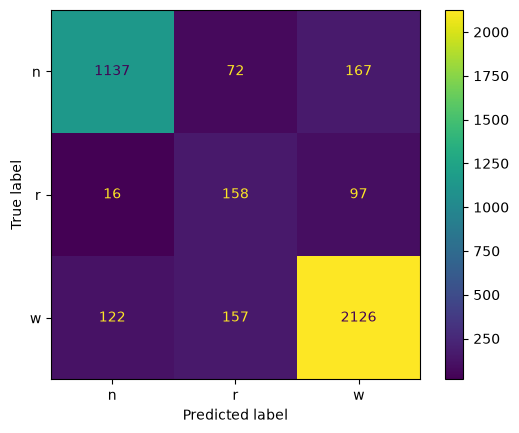

In [9]:
cm = confusion_matrix(Y_test, Y_pred, labels=rf_classifier.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_classifier.classes_)
disp.plot()
plt.show()

### FEATURES IMPORTANCE

The following graph represents the importance of each feature for the classification.

Q2.11: How is this importance calculated?

**A2.11**: It corresponds to the mean decrease in impurity, i.e. on average, how much the impurity decreases when splitting the dataset using each feature

Q2.12: What can you conclude from this graph?

**A2.12**: We can conclude that only a handful of features are important, and less than 10 really have an impact. This corresponds to the computed optimal hyper-parameters for which we chose `max_features=18`

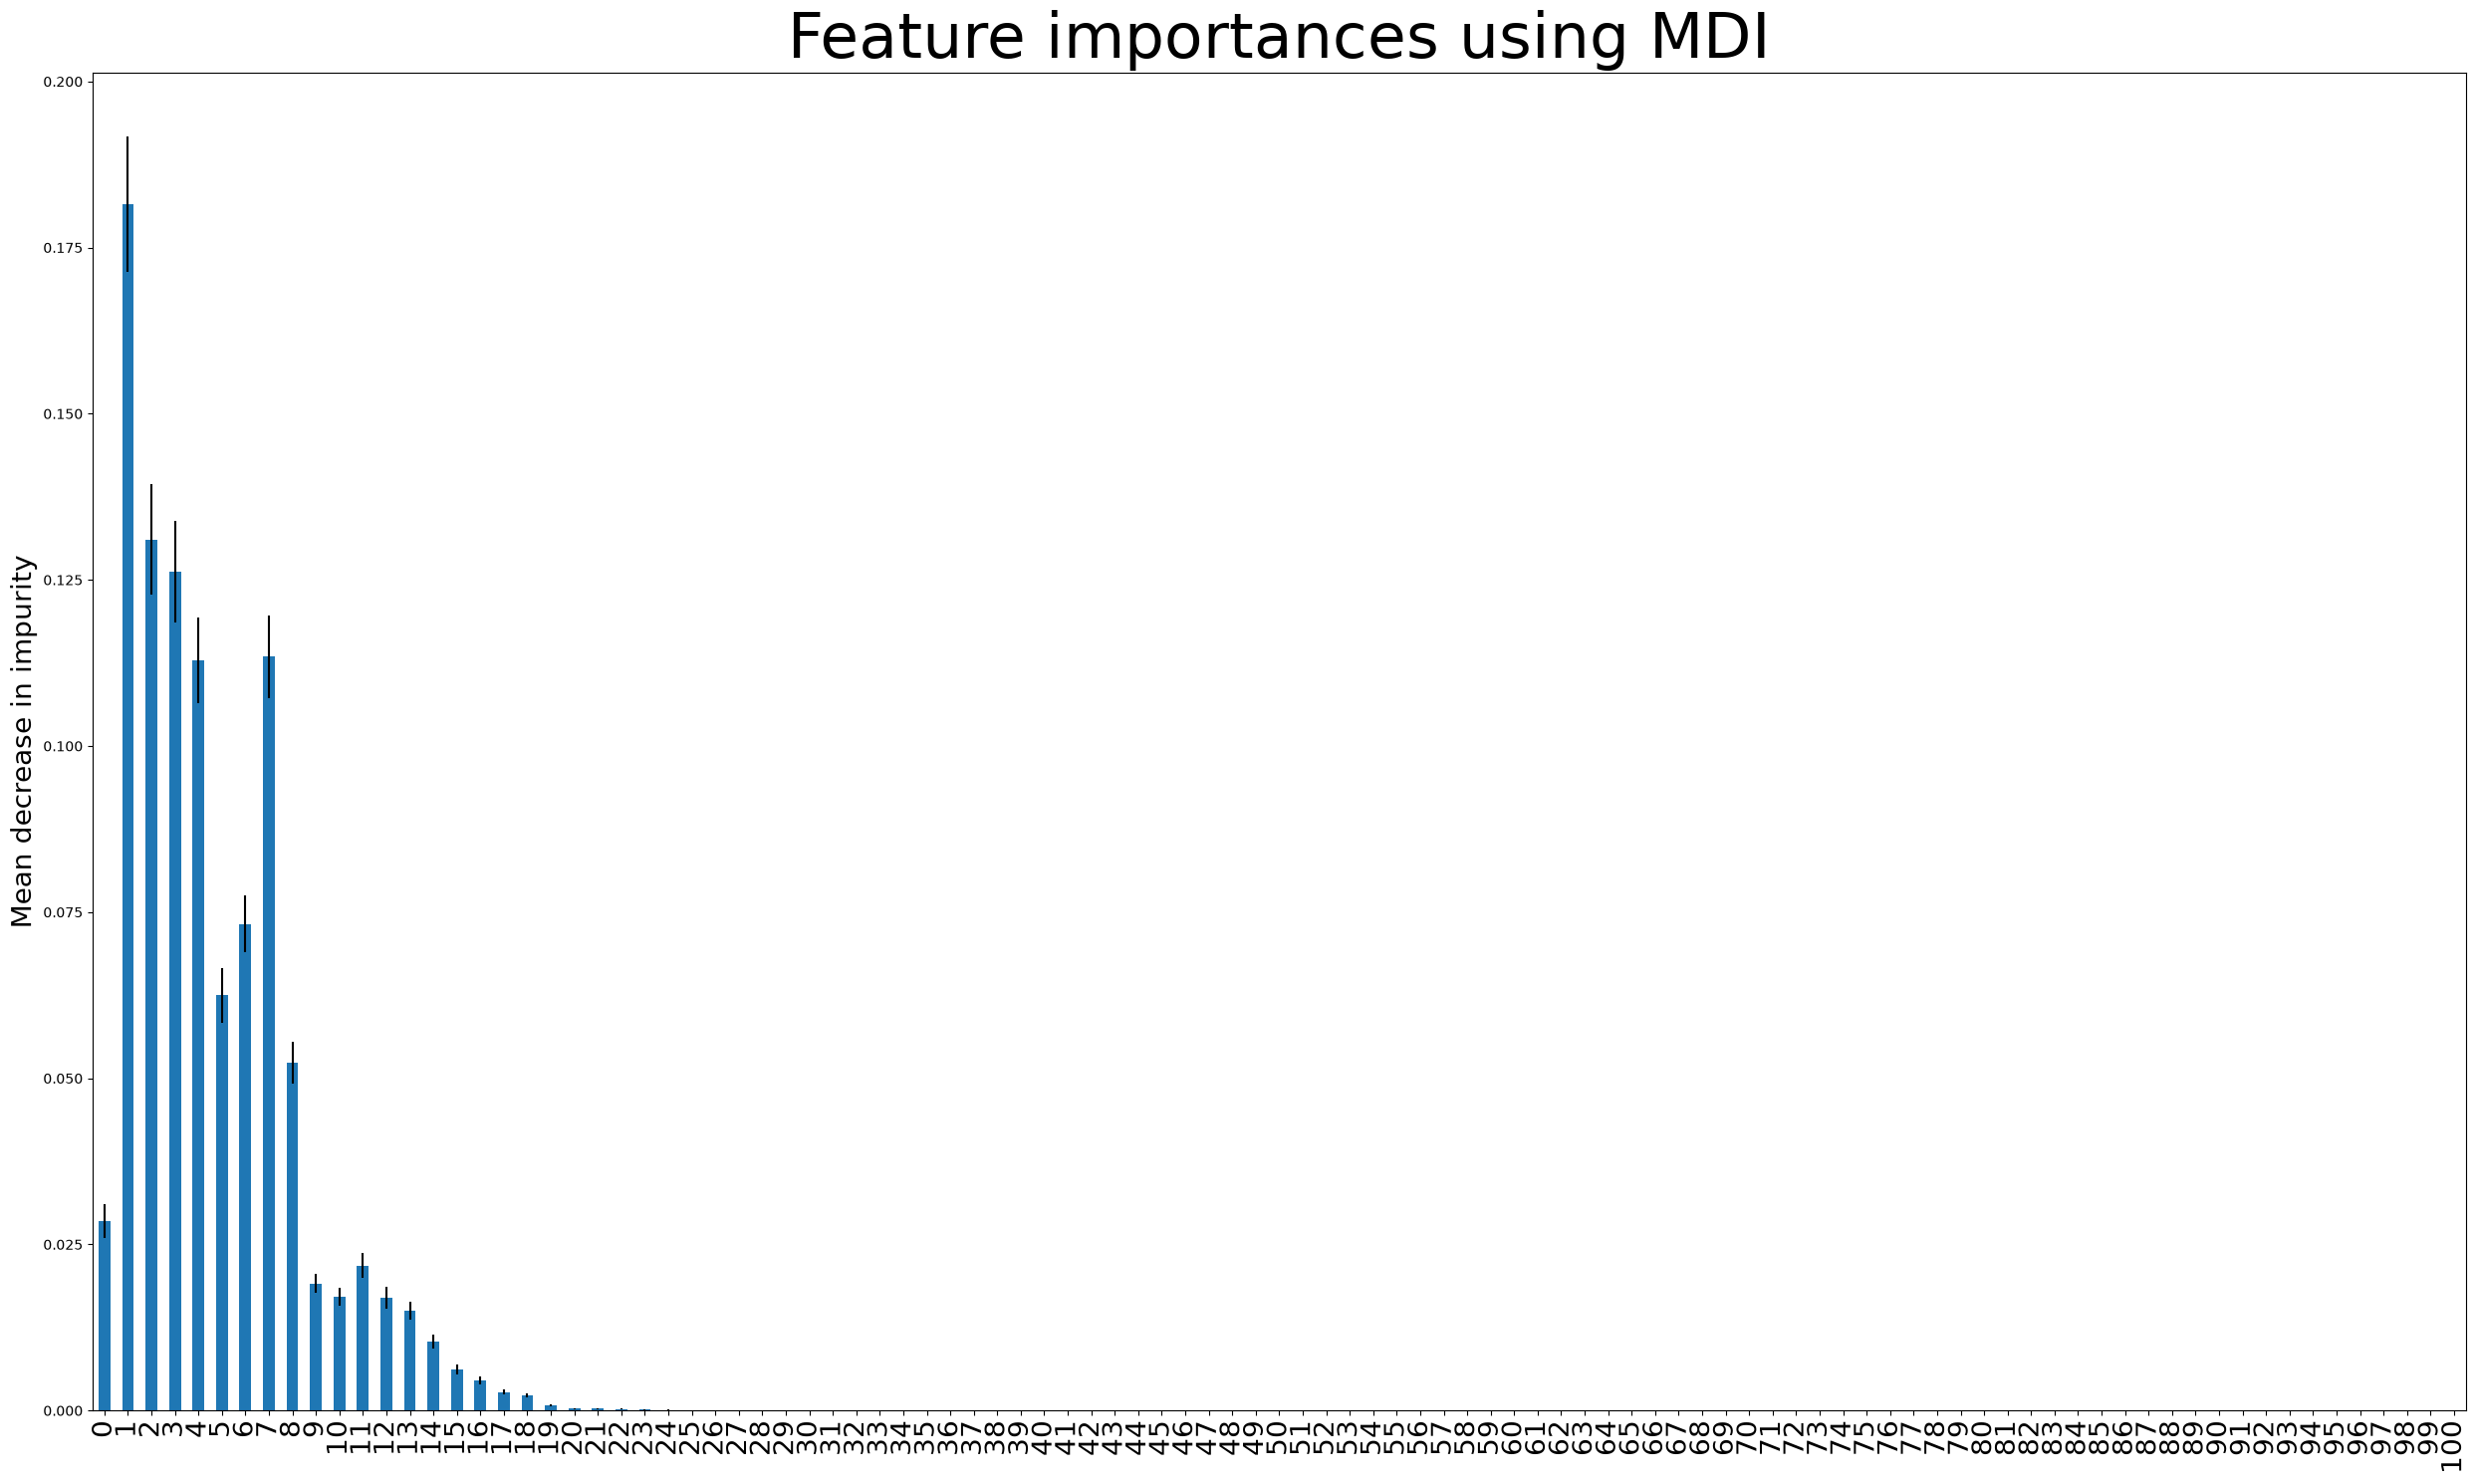

In [10]:
# Calculate feature importances and SEM
importances = rf_classifier.feature_importances_
n_trees = len(rf_classifier.estimators_)
std = np.std([tree.feature_importances_ for tree in rf_classifier.estimators_], axis=0)
sem = std / np.sqrt(n_trees)

# Plot features importance
forest_importances = pd.Series(importances)
fig, ax = plt.subplots(figsize=(25, 15))
plt.xticks(rotation=90, fontsize=20)
forest_importances.plot.bar(ax=ax, yerr=sem)  # Use SEM for error bars
ax.set_title("Feature importances using MDI", fontsize=45)
ax.set_ylabel("Mean decrease in impurity", fontsize=20)
fig.tight_layout()